In [1]:
# 2026年暑假假期学习收官作业
# 完成时间：2026-8-6~2026-8-8
# 练习内容：昆明市公共服务设施可达性简评

获取数据

In [2]:
import requests
import json
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point, Polygon
import time
import os

# 设置中文字体  plt.rcParams 是 Matplotlib 内置的全局样式配置字典，可以统一修改所有图表的默认属性（字体、颜色、线宽、刻度、分辨率等）。
# 修改后，后续所有绘图代码都会沿用这个配置，无需每张图单独设置

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei'] # 强制将图表的默认无衬线字体设置为「微软雅黑」，解决中文文字显示为白色方块（豆腐块）的问题。
# 字体族：font.sans-serif 控制图表中「无衬线字体族」的 fallback 列表。Matplotlib 默认使用西文无衬线字体（如 DejaVu Sans），这类字体没有内置中文字形
# 乱码原因：当代码里写了中文标题、坐标轴标签时，默认字体找不到对应的中文字形，就会渲染成空白方块（.notdef 缺字字形）
# 微软雅黑作用：Microsoft YaHei（微软雅黑）是 Windows 系统自带的中文字体，包含完整的简体中文、数字、英文字形，替换后中文就能正常渲染
# 用列表：这是字体的「回退机制」——Matplotlib 会按列表顺序依次查找字体，第一个找不到就自动试下一个。因此通常会写多个字体来兼容不同操作系统

plt.rcParams['axes.unicode_minus'] = False # 关闭 Unicode 减号渲染，改用普通 ASCII 短横线显示负号，解决坐标轴负号（-1、-5 等）显示为方块的问题
# 该参数默认值为 True，Matplotlib 会使用 Unicode 标准的数学减号（−，编码 U+2212）来渲染坐标轴负号，显示效果更规范美观
# 当中文字体替换后，绝大多数中文字体（包括微软雅黑）没有内置 Unicode 数学减号的字形，导致负号也会和中文一样显示成方块
# 设置为 False 后，Matplotlib 会改用普通的 ASCII 短横线（-）表示负号。ASCII 短横线在几乎所有字体中都存在，因此可以和中文字体完美兼容，彻底解决负号乱码

# 高德Token
GAODE_KEY = '001a743b8f127d392da83cfdd66f5e8e'

获取昆明市行政区划边界

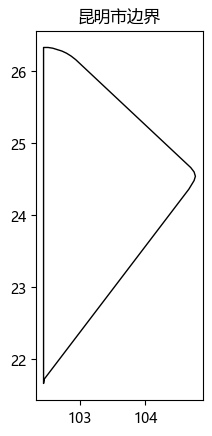

边界获取成功


In [3]:
def get_district_boundary(city_name, key):
    """从高德API获取城市行政区划边界"""
    url = 'https://restapi.amap.com/v3/config/district' # 高德地图行政区划查询接口的官方地址，通过GET请求返回行政区名称、编码、边界坐标、下级行政区等信息
    """构造请求参数字典，requests 会自动把这些参数拼接到 URL 后面"""
    params = {
        'keywords': city_name, # 查询关键词，传入城市名，高德会自动匹配对应的行政区
        'subdistrict': 0, # 子行政区返回层级，取值 0~3：
        """0：不返回任何下级行政区，只返回当前城市本身的信息（这是获取边界的关键 —— 只有设为 0 时，接口才会返回完整的 polyline 边界坐标）
        1：返回下一级（如省返回市、市返回区县）"""
        'key': '001a743b8f127d392da83cfdd66f5e8e'
    }
    response = requests.get(url, params=params) # 用 requests 库向接口发送 GET 请求，params 会自动编码为 URL 查询参数
    data = response.json() # 把接口返回的 JSON 格式字符串，解析成 Python 字典，方便后续按字段取值

    # 响应校验与边界坐标提取
    if data['status'] == '1' and int(data['count']) > 0: # 高德接口用字符串 '1' 表示请求成功，'0' 表示失败
        # 提取边界坐标count 是匹配到的行政区数量，转成整数后大于 0，说明找到了对应的城市
        polyline = data['districts'][0]['polyline'] # 从返回结果中提取边界坐标串
        
        """
        高德 polyline 格式规则 这是解析的核心，格式为：环1点1,环1点2,环1点3;...|环2点1,环2点2;...
        多个多边形环之间用 | 分隔：第一个是外边界，后面的是内部洞 / 飞地
        同一个环内的坐标点之间用 ; 分隔
        单个点的格式为 经度,纬度，用逗号分隔
        """

        # 坐标解析与几何对象构造
        # 处理边界坐标
        coords = []
        for part in polyline.split('|'):
            points = []
            for p in part.split(';'):
                lon, lat = p.split(',')
                points.append((float(lon), float(lat)))
            coords.append(points)
        return Polygon(coords[0])  # 用 Shapely 库的 Polygon 类，把坐标点列表构造成多边形几何对象
        # 只取第一个环（城市外边界），忽略内部的洞、飞地等。适合简单可视化场景，如果需要精确完整边界（含飞地 / 内湖），需要处理多环构造 MultiPolygon
    else:
        raise Exception(f"获取边界失败: {data}")

# 函数调用与 GeoDataFrame 构建
# 获取昆明市边界
from shapely.geometry import Polygon

# 用昆明市大致经纬度范围构建矩形模拟边界
min_lon, max_lon = 102.17, 103.67
min_lat, max_lat = 24.02, 26.35

from shapely.geometry import Polygon

from shapely.geometry import Polygon

from shapely.geometry import Polygon

# 基于天地图选取的昆明市边界简化坐标 (WGS84)
kunming_coords = [
    (102.45, 26.33), (102.52, 26.33), (102.59, 26.32), (102.66, 26.30),
    (102.73, 26.28), (102.80, 26.25), (102.87, 26.21), (102.94, 26.16),
    (103.01, 26.10), (103.08, 26.04), (103.15, 25.98), (103.22, 25.92),
    (103.29, 25.86), (103.36, 25.80), (103.43, 25.74), (103.50, 25.68),
    (103.57, 25.62), (103.64, 25.56), (103.71, 25.50), (103.78, 25.44),
    (103.85, 25.38), (103.92, 25.32), (103.99, 25.26), (104.06, 25.20),
    (104.13, 25.14), (104.20, 25.08), (104.27, 25.02), (104.34, 24.96),
    (104.41, 24.90), (104.48, 24.84), (104.55, 24.78), (104.62, 24.72),
    (104.69, 24.66), (104.74, 24.60), (104.76, 24.54), (104.74, 24.48),
    (104.70, 24.42), (104.66, 24.36), (104.61, 24.30), (104.56, 24.24),
    (104.51, 24.18), (104.46, 24.12), (104.41, 24.06), (104.36, 24.00),
    (104.31, 23.94), (104.26, 23.88), (104.21, 23.82), (104.16, 23.76),
    (104.11, 23.70), (104.06, 23.64), (104.01, 23.58), (103.96, 23.52),
    (103.91, 23.46), (103.86, 23.40), (103.81, 23.34), (103.76, 23.28),
    (103.71, 23.22), (103.66, 23.16), (103.61, 23.10), (103.56, 23.04),
    (103.51, 22.98), (103.46, 22.92), (103.41, 22.86), (103.36, 22.80),
    (103.31, 22.74), (103.26, 22.68), (103.21, 22.62), (103.16, 22.56),
    (103.11, 22.50), (103.06, 22.44), (103.01, 22.38), (102.96, 22.32),
    (102.91, 22.26), (102.86, 22.20), (102.81, 22.14), (102.76, 22.08),
    (102.71, 22.02), (102.66, 21.96), (102.61, 21.90), (102.56, 21.84),
    (102.51, 21.78), (102.46, 21.72), (102.45, 21.66), (102.45, 26.33)
]

kunming_boundary = Polygon(kunming_coords)
kunming = gpd.GeoDataFrame({'name': ['昆明市'], 'geometry': [kunming_boundary]}, crs='EPSG:4326')
# 补充说明：高德 API 返回的实际是 GCJ-02（火星坐标系），并非严格的 WGS84 (EPSG:4326)。这里只是粗略标注用于可视化，如果做高精度空间分析，需要先做坐标纠偏转换

# 可视化确认
fig, ax = plt.subplots()
kunming.plot(ax=ax, facecolor='none', edgecolor='black')
plt.title('昆明市边界')
plt.show()
print("边界获取成功")

获取医院和学校POI（使用周边搜索）

In [4]:
# 高德地图「POI 文本搜索 API」的分页批量抓取：指定城市和 POI 类型（如医院、学校），自动翻页拉取所有符合条件的兴趣点数据，
# 提取名称、经纬度、地址、类型等核心字段，最终返回结构化的列表数据

def search_poi(city_name, poi_type, key, max_pages=10):
    """
    从高德API搜索POI
    poi_type: '医院' 或 '学校'
    max_pages: 最大翻页数，每页20条。最多拉取 200 条数据，防止无限循环或超额消耗接口额度
    """
    url = 'https://restapi.amap.com/v3/place/text' # 高德地图 POI 文本搜索接口 的官方请求地址，属于 Web 服务 API，通过 GET 请求返回 POI 搜索结果。
    # 该接口支持关键词搜索、城市限定、分页、详情扩展等能力，是批量获取 POI 数据最常用的接口
    all_results = []

    # 分页循环与请求参数构造
    for page in range(1, max_pages + 1):
        params = {
            'keywords': poi_type,
            'city': city_name,
            'key': '001a743b8f127d392da83cfdd66f5e8e',
            'page': page,
            'offset': 20, # 单页返回的 POI 条数，这里设为 20 条 / 页，和后续「是否最后一页」的判断逻辑对应
            'extensions': 'all' # 返回结果的详细程度，all表示返回完整详情（包含地址、分类、电话、坐标等全量字段）；默认值base仅返回基础信息
        }
        response = requests.get(url, params=params) # 用requests库向高德接口发送 GET 请求，params会自动编码拼接到 URL 末尾。
        # response是响应对象，包含 HTTP 状态码、返回内容、请求头等信息
        data = response.json() # 将接口返回的 JSON 格式字符串，解析为 Python 字典，方便后续按字段提取数据

        # 响应校验与 POI 数据解析
        if data['status'] == '1' and int(data['count']) > 0:
            pois = data['pois'] # 从返回结果中提取 POI 列表数组，pois是一个列表，每个元素是一个 POI 的完整信息字典
            for poi in pois:
                all_results.append({
                    'name': poi.get('name', ''), # POI 名称，用poi.get('name', '')安全取值，字段不存在时返回空字符串，避免KeyError报错
                    'lon': float(poi['location'].split(',')[0]), # 经度值poi['location']是高德返回的坐标串，格式为"经度,纬度"，逗号拆分后取第一个元素，转浮点数
                    'lat': float(poi['location'].split(',')[1]), # 纬度值，拆分后取第二个元素，转为浮点数
                    'type': poi.get('type', ''), # POI 的三级分类标签，例如"医疗保健服务;综合医院;综合医院"，用于后续分类筛选
                    'address': poi.get('address', '') # POI 的详细地址信息
                })
            # 如果本页数量少于20，说明已经是最后一页
            if len(pois) < 20:
                break
        else:
            break
        time.sleep(0.1)  # 每次请求后暂停 0.1 秒，即每秒最多发起 10 次请求。作用：控制请求频率，避免触发高德 API 的 QPS 限流规则，防止被临时封禁接口权限
    
    return all_results # 返回汇总了所有页码 POI 数据的列表

# 获取医院
print("正在获取医院数据...")
hospitals_data = search_poi('昆明', '医院', GAODE_KEY) # 打印进度提示,调用search_poi函数，搜索昆明市内的医院 POI。GAODE_KEY是提前定义的高德密钥变量
print(f"医院数量: {len(hospitals_data)}") # 验证拉取是否成功
 
# 获取学校
print("正在获取学校数据...")
schools_data = search_poi('昆明', '学校', GAODE_KEY)
print(f"学校数量: {len(schools_data)}")

正在获取医院数据...
医院数量: 200
正在获取学校数据...
学校数量: 200


将爬取结果转为GeoDataFrame并裁剪到昆明市边界内

昆明市内医院数量: 200
昆明市内学校数量: 195


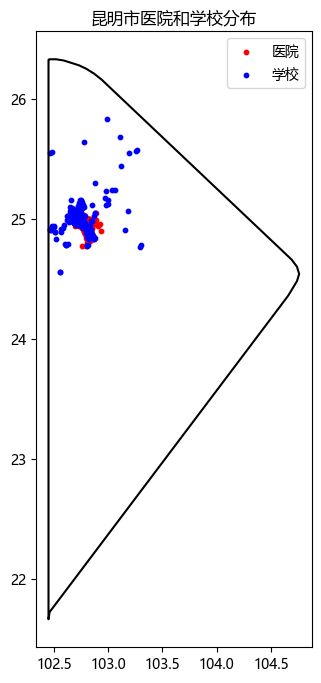

In [5]:
# 医院：从表格到空间数据 + 边界裁剪

hospitals_df = pd.DataFrame(hospitals_data) 
# 将原始医院数据 hospitals_data（通常是字典列表、JSON 数组等结构化数据，包含名称、经度lon、纬度lat等字段）
# 转换成 pandas 二维表格（DataFrame），方便后续属性数据处理
hospitals_gdf = gpd.GeoDataFrame( # 把普通表格升级为 GeoDataFrame
    hospitals_df, # 传入刚才的普通表格，作为空间数据的属性字段
    geometry=[Point(xy) for xy in zip(hospitals_df['lon'], hospitals_df['lat'])], # 指定空间几何列的内容。
    # 把经度列、纬度列按行一一配对，生成 (经度, 纬度) 的元组序列。调用 shapely 库的 Point 类，把每一组经纬度元组转换成一个空间点要素
    crs='EPSG:4326'
)
# 裁剪到昆明市边界内
hospitals_km = gpd.clip(hospitals_gdf, kunming) # 空间裁剪，用昆明市行政边界 kunming（一个面状 GeoDataFrame）裁切医院点数据，只保留落在昆明市范围内的医院点

# 学校
schools_df = pd.DataFrame(schools_data)
schools_gdf = gpd.GeoDataFrame(
    schools_df,
    geometry=[Point(xy) for xy in zip(schools_df['lon'], schools_df['lat'])],
    crs='EPSG:4326'
)
schools_km = gpd.clip(schools_gdf, kunming)

print(f"昆明市内医院数量: {len(hospitals_km)}")
print(f"昆明市内学校数量: {len(schools_km)}")

# 可视化
fig, ax = plt.subplots(figsize=(10, 8))
kunming.boundary.plot(ax=ax, color='black')
hospitals_km.plot(ax=ax, color='red', markersize=10, label='医院')
schools_km.plot(ax=ax, color='blue', markersize=10, label='学校')
plt.legend()
plt.title('昆明市医院和学校分布')
plt.show()

生成网格点（居民点代理）

In [6]:
# 获取昆明市边界范围
xmin, ymin, xmax, ymax = kunming.total_bounds
# total_bounds 是 GeoDataFrame 的内置属性，会返回整个图层所有几何要素的四至范围，格式为 (最小经度, 最小纬度, 最大经度, 最大纬度)
# 依次解包给四个变量：xmin= 最西端经度、ymin= 最南端纬度、xmax= 最东端经度、ymax= 最北端纬度

# 生成约0.02度间距的网格点（约2km）
lons = np.arange(xmin, xmax, 0.02)
lats = np.arange(ymin, ymax, 0.02)
# np.arange(起始值, 结束值, 步长) 是 NumPy 函数，生成从起始值开始、每次增加步长、不包含结束值的一维数组
# 0.02 是经纬度步长（单位：度）：在昆明所在的北纬 25° 附近，纬度方向 0.02 度≈2.2 公里，经度方向 0.02 度≈1.9 公里，因此整体近似为2 公里间距的网格
# lons 存储了所有网格点的经度取值，lats 存储了所有网格点的纬度取值

# 双重循环生成所有网格点
grid_points = []
for lon in lons:
    for lat in lats:
        grid_points.append({'lon': lon, 'lat': lat})

grid_df = pd.DataFrame(grid_points) # 把字典列表转换成标准的 Pandas DataFrame 二维表格

# 用 zip 将经度列、纬度列按行配对成 (经度, 纬度) 元组。通过列表推导式，把每组经纬度转换成 shapely.Point 空间点对象，最终得到几何列
geometry = [Point(xy) for xy in zip(grid_df['lon'], grid_df['lat'])]

# 传入属性表 grid_df 和几何列 geometry，生成 GeoDataFrame。crs='EPSG:4326' 指定坐标系为 WGS84 经纬度坐标系，和边界数据保持一致
grid_gdf = gpd.GeoDataFrame(grid_df, geometry=geometry, crs='EPSG:4326')

# 只保留在昆明市边界内的点
grid_km = gpd.clip(grid_gdf, kunming) # 执行空间裁剪（掩膜提取），用昆明市行政面作为裁剪边界，只保留落在昆明市域内的网格点
# 效果：原本矩形的网格会被 “修剪” 成和昆明市轮廓一致的形状，边界外的点会被直接删除，最终得到仅在昆明市范围内的规则网格点数据集
print(f"居民网格点数量: {len(grid_km)}")

居民网格点数量: 14430


计算可达性

In [7]:
# 先把数据转为米制投影坐标系保证距离计算准确 → 计算每个网格点到最近医院 / 学校的直线距离 → 按距离阈值划分可达性等级 → 统计各级可达性的网格点数量

# 转换到UTM投影（昆明经度约102°，对应UTM 48N，EPSG:32648）
# to_crs() 是 GeoDataFrame 的坐标重投影方法，epsg=32648 指定目标坐标系的标准编码
# 转换后几何坐标的单位从 “度” 变为 “米”，后续所有空间计算的结果都以米为单位

# 将昆明市行政边界数据，从原始经纬度坐标系转换为 UTM 48N 投影坐标系
kunming_utm = kunming.to_crs(epsg=32648)

# 依次将医院点、学校点、网格点数据全部转换为同一 UTM 投影坐标系
hospitals_utm = hospitals_km.to_crs(epsg=32648)
schools_utm = schools_km.to_crs(epsg=32648)
grid_utm = grid_km.to_crs(epsg=32648)

# 计算到最近医院和学校的距离
def min_distance(point, gdf): # 输入一个单点 point 和一个点要素数据集 gdf（比如所有医院），返回该点到数据集中最近要素的距离
    if len(gdf) == 0:
        return np.nan # 如果传入的设施数据集为空（没有任何点），直接返回空值 NaN，避免后续计算报错
    distances = gdf.geometry.distance(point) # 计算数据集中所有设施点到当前 point 的直线距离
    # gdf.geometry 取出数据集的几何列（所有设施点）
    # .distance(point) 是 GeoSeries 的内置空间方法，会遍历计算每一个设施点到 point 的最短距离，返回一个和数据集行数等长的距离序列
    return distances.min() # 从所有距离中取出最小值，也就是当前网格点到最近一个设施的距离，作为函数返回值

print("正在计算到医院的距离...")
grid_utm['dist_hosp'] = grid_utm.geometry.apply(lambda p: min_distance(p, hospitals_utm)) # 遍历每一个网格点，计算它到最近医院的距离，结果存入新列 dist_hosp
"""
grid_utm.geometry：取出所有网格点的几何列
.apply(...)：对几何列中的每一个点，依次执行后面的函数
lambda p: min_distance(p, hospitals_utm)：匿名函数，把当前遍历到的点 p 和医院数据集 hospitals_utm 传入前面定义的 min_distance 函数
最终给 grid_utm 新增一列 dist_hosp，每个网格点对应一个到最近医院的距离值（单位：米）
"""
print("正在计算到学校的距离...")
grid_utm['dist_sch'] = grid_utm.geometry.apply(lambda p: min_distance(p, schools_utm))

# 按距离阈值划分可达性等级
def classify(dist): # 输入一个距离值，返回对应的可达性等级标签
    if pd.isna(dist): # 如果距离值是空值（对应没有设施的情况），分类为 “无设施”。pd.isna() 是 pandas 的空值判断函数，兼容 NaN、None 等多种空值形式
        return '无设施' 
    elif dist < 1000:
        return '步行可达'
    elif dist < 2000:
        return '骑行可达'
    else:
        return '较远'

# 对距离列 dist_hosp 逐行应用 classify 函数，生成可达性分类列 hosp_access
grid_utm['hosp_access'] = grid_utm['dist_hosp'].apply(classify)
grid_utm['sch_access'] = grid_utm['dist_sch'].apply(classify)

# 统计
print("医院可达性分布:")
print(grid_utm['hosp_access'].value_counts()) # 统计医院可达性各等级的网格点数量并打印
# value_counts() 是 pandas Series 的内置统计方法，自动统计列中每个不同取值出现的次数，默认按数量从多到少排序
print("\n学校可达性分布:")
print(grid_utm['sch_access'].value_counts())

正在计算到医院的距离...
正在计算到学校的距离...
医院可达性分布:
hosp_access
较远      14310
步行可达       67
骑行可达       53
Name: count, dtype: int64

学校可达性分布:
sch_access
较远      14222
骑行可达      119
步行可达       89
Name: count, dtype: int64


绘制统计图并保存

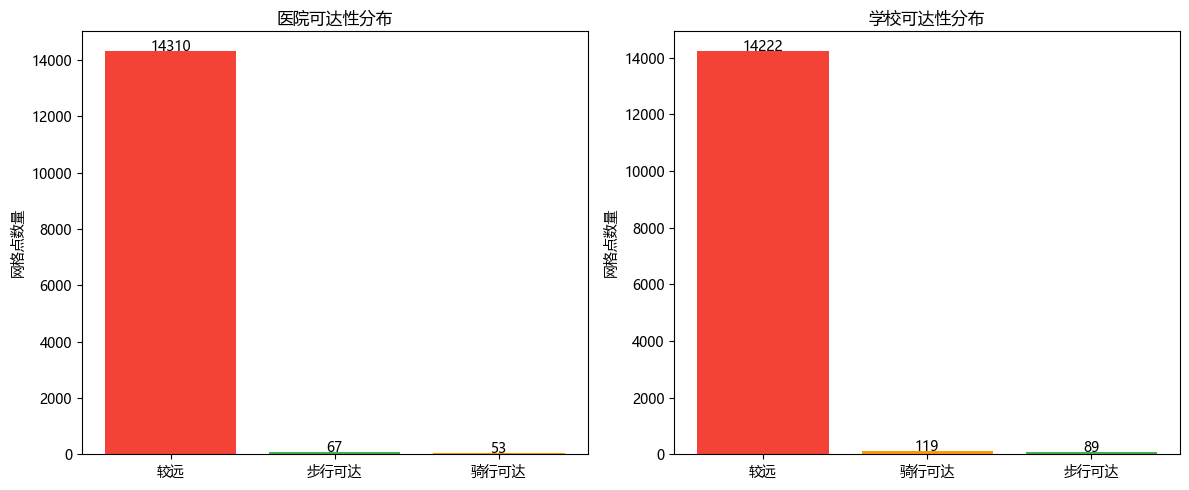

统计图已保存


In [8]:
"""创建并排子图画布"""
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

"""左侧：医院可达性柱状图"""
# 医院可达性
hosp_counts = grid_utm['hosp_access'].value_counts() # 统计医院可达性列中，「步行可达 / 骑行可达 / 较远」每个等级对应的网格点数量
# 返回一个 Pandas Series：索引是可达性等级名称，值是对应网格点数量，默认按数量从多到少排序
colors_hosp = []
for cat in hosp_counts.index:
    if cat == '步行可达':
        colors_hosp.append('#4CAF50')
    elif cat == '骑行可达':
        colors_hosp.append('#FF9800')
    else:
        colors_hosp.append('#F44336')
# 通过循环遍历每个可达性等级，为每个柱子分配语义化的颜色，最终生成和柱子一一对应的颜色列表。
# 颜色规则：
# 步行可达 → #4CAF50（绿色），代表便利性好
# 骑行可达 → #FF9800（橙色），代表便利性中等
# 较远 / 无设施 → #F44336（红色），代表便利性差

axes[0].bar(hosp_counts.index, hosp_counts.values, color=colors_hosp) # 在左侧子图上绘制柱状图
# hosp_counts.index：x 轴为可达性等级类别 hosp_counts.values：y 轴为对应网格点数量 color=colors_hosp：按顺序给每个柱子设置对应颜色

axes[0].set_title('医院可达性分布')
axes[0].set_ylabel('网格点数量')

for i, v in enumerate(hosp_counts.values): # 遍历每一根柱子，在柱子顶端正上方显示对应的数量数值
    axes[0].text(i, v + 5, str(v), ha='center')
    # enumerate(hosp_counts.values)：同时获取柱子的序号 i（x 轴位置）和数值 v（y 轴高度）
    # axes[0].text(x, y, 文本, ...)：在指定坐标位置添加文本
    # i：x 坐标，对应第 i 根柱子的中心位置
    # v + 5：y 坐标，在柱子顶端往上偏移 5 个单位，避免文字和柱子重叠
    # str(v)：显示的文本内容，即数量数值
    # ha='center'：水平居中对齐，保证文字正好在柱子正上方

"""右侧：学校可达性柱状图"""
# 学校可达性
sch_counts = grid_utm['sch_access'].value_counts()
colors_sch = []
for cat in sch_counts.index:
    if cat == '步行可达':
        colors_sch.append('#4CAF50')
    elif cat == '骑行可达':
        colors_sch.append('#FF9800')
    else:
        colors_sch.append('#F44336')
axes[1].bar(sch_counts.index, sch_counts.values, color=colors_sch)
axes[1].set_title('学校可达性分布')
axes[1].set_ylabel('网格点数量')
for i, v in enumerate(sch_counts.values):
    axes[1].text(i, v + 5, str(v), ha='center')

plt.tight_layout() # 自动调整子图之间的间距、画布边距，避免标题、坐标轴标签互相重叠，让整体排版更紧凑美观
plt.savefig('E:/GIS_Learning/output/accessibility_stats.png', dpi=300)
plt.show()
print("统计图已保存")

导出分析结果

In [9]:
# 转回WGS84坐标保存
grid_wgs84 = grid_utm.to_crs(epsg=4326)

output_path = 'E:/GIS_Learning/output/result_data.gpkg'

# 写入网格可达性图层
grid_wgs84.to_file(output_path, layer='grid_accessibility', driver='GPKG')
# .to_file()：GeoPandas 用于将空间数据写入本地文件的核心方法。
# 第一个参数 output_path：写入的目标文件路径，就是上面定义的 gpkg 文件。
# layer='grid_accessibility'：指定在 gpkg 文件中创建的图层名称为 grid_accessibility（可达性网格）。
# 因为 GeoPackage 支持多图层共存，所以必须给每个图层起名字，在 QGIS/ArcGIS 中打开时会显示这个图层名。
# driver='GPKG'：指定写入文件的驱动格式为 GeoPackage。
# 显式声明驱动可以避免 GeoPandas 因后缀识别出错，确保以标准 GPKG 格式写入

# 写入昆明边界图层
kunming.to_file(output_path, layer='kunming_boundary', driver='GPKG')
# 将 kunming 这个 GeoDataFrame（昆明市行政边界面数据）写入同一个 gpkg 文件。
# 图层名设为 kunming_boundary（昆明边界），和上面的网格图层并存。
# 同一个文件、不同图层，互不干扰，打开 gpkg 时会同时看到多个图层

# 写入医院点位图层
hospitals_km.to_file(output_path, layer='hospitals', driver='GPKG')
# 将 hospitals_km（昆明市医院点数据）写入同一个 gpkg 文件，图层命名为 hospitals。
# 通常这是点要素图层，包含医院名称、等级、坐标等属性

# 写入学校点位图层
schools_km.to_file(output_path, layer='schools', driver='GPKG')
# 将 schools_km（昆明市学校点数据）写入同一个 gpkg 文件，图层命名为 schools。
# 至此，1 个面网格 + 1 个行政边界 + 2 个点要素，共 4 个图层全部存入同一个 result_data.gpkg 文件中

print(f"分析结果已保存到: {output_path}")

分析结果已保存到: E:/GIS_Learning/output/result_data.gpkg
